# Fit a 3-state Markov Chain + HMM and generate paths (paper style)

This notebook fits, to our **segmented bouts** (`data/bouts_GsizeMotionSingle.csv`, from `segment_bouts.ipynb`), the two models of **Dommanget-Kott et al. 2026** (*Linking brain and behavior states ... using hidden Markov models*, PLoS Comput Biol) and then **generates synthetic swim trajectories** from the HMM, as in the paper's Fig 6.

**1. Markov Chain (MC)** — threshold `dtheta` at ±10° into Forward / Left / Right and count transitions (paper Eq 2). Mirrors the paper repo `utils/MarkovChains.py`.

**2. Hidden Markov Model (HMM, `G3_Sym`)** — 3 hidden states with emissions
- **F**: `Normal(dtheta; 0, sigma)` (centered forward),
- **L**: `Gamma(-dtheta; alpha, theta)` on `dtheta < 0`,
- **R**: `Gamma(+dtheta; alpha, theta)` on `dtheta > 0`,

with **left–right symmetry** on the transition matrix / initial distribution and one shared turn Gamma (`alpha >= 1`). This is exactly the emission set stored in the paper's fitted models (`sforw` scalar + `turn = [alpha, theta]`, `dtheta` in **degrees**).

**Optimisation = Baum-Welch (EM).** The paper's “custom Julia implementation” (`ZebrafishHMM2023.jl`) is the generic Baum-Welch of `HiddenMarkovModels.jl` specialised to this emission type — there is no other optimizer. We reproduce it in Python in `scripts/fit_hmm.py` (log-space forward–backward + a symmetric, tied M-step with a weighted Gamma MLE for the turn emission; up to 500 EM iters, stop when the log-likelihood gain < 1e-6, random symmetric restarts, keep the best).

**Generation** (paper Sect 2.7.2): sample a state sequence from the HMM, sample an angle from each state's emission, resample `dt`/`dist` from the **empirical** pools (bout-type-independent), reconstruct x,y by cumulative sums (Eq 5).

> Heads-up: our reorientation distribution is far broader than the paper's freely-swimming data (median `|dtheta|` ≈ 39° vs ~10°), so expect a **large forward sigma** and less crisp states. This is an honest limit of the integer-pixel tracking, not the fit.

## 1. Setup & load per-trajectory sequences

We import the fitting code from `scripts/fit_hmm.py` (so the notebook and the CLI stay in sync), then split the bout table into one `dtheta` sequence per continuous trajectory `(fish_id, segment_id)`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, gamma as gamma_dist

ROOT = Path.cwd()
if not (ROOT / "scripts").exists() and (ROOT.parent / "scripts").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import fit_hmm as H   # our paper-style MC + HMM implementation

BOUTS_CSV = ROOT / "data" / "bouts_GsizeMotionSingle.csv"
df = pd.read_csv(BOUTS_CSV)
MIN_LEN = 10                      # min bouts per trajectory to keep
seqs = H.load_sequences_from_bouts(df, min_len=MIN_LEN)
n_bouts = sum(len(s) for s in seqs)
print(f"{len(seqs)} trajectories, {n_bouts} bouts (min_len={MIN_LEN})")
print(f"median |dtheta| = {np.median(np.abs(np.concatenate(seqs))):.1f} deg")

15 trajectories, 70771 bouts (min_len=10)
median |dtheta| = 39.0 deg


## 2. Markov Chain — threshold labeling at ±10°

The baseline the paper compares against: classify each bout by its angle (`|dtheta| < 10°` = forward, else left/right by sign) and estimate the transition matrix by counting (paper Eq 2).

state fractions (F,L,R): [0.111 0.448 0.44 ]
steady state          : [0.111 0.448 0.44 ]


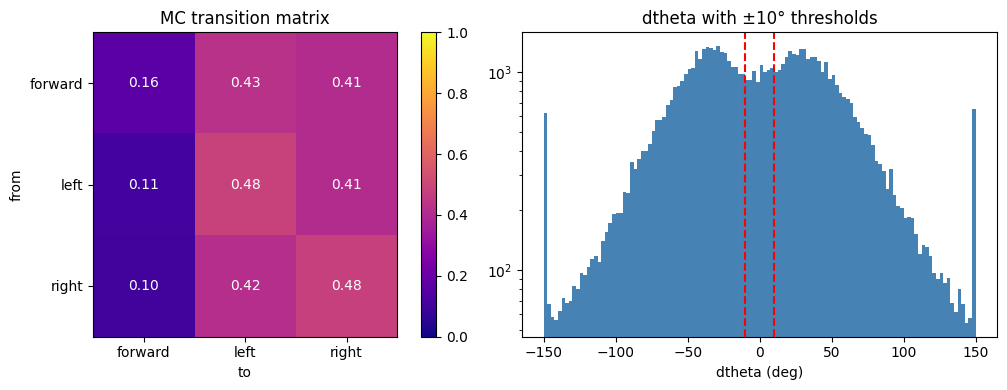

In [2]:
bout_seqs = H.threshold_classifier(seqs, dtheta0=H.DTHETA0_DEG)
P_mc = H.bout_transitions(bout_seqs)
pi_mc = H.bout_proba(bout_seqs)
print("state fractions (F,L,R):", np.round(pi_mc, 3))
print("steady state          :", np.round(H.steady_state(P_mc), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(P_mc, vmin=0, vmax=1, cmap="plasma", origin="upper")
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, f"{P_mc[i,j]:.2f}", ha="center", va="center", color="w")
ax[0].set_xticks(range(3), H.STATE_NAMES); ax[0].set_yticks(range(3), H.STATE_NAMES)
ax[0].set_xlabel("to"); ax[0].set_ylabel("from"); ax[0].set_title("MC transition matrix")
fig.colorbar(im, ax=ax[0], fraction=0.046)

alld = np.concatenate(seqs)
ax[1].hist(np.clip(alld, -150, 150), bins=120, color="steelblue")
ax[1].axvline(H.DTHETA0_DEG, color="r", ls="--"); ax[1].axvline(-H.DTHETA0_DEG, color="r", ls="--")
ax[1].set_yscale("log"); ax[1].set_xlabel("dtheta (deg)"); ax[1].set_title("dtheta with ±10° thresholds")
plt.tight_layout(); plt.show()

## 3. Fit the HMM by Baum-Welch

This is the heavy step (log-space forward–backward + symmetric EM, a few random restarts). A couple of restarts is enough to see the structure; increase `restarts` for the paper's more thorough search.

  restart 0: loglik=-385196.5  iters=202  sigma=6.23 alpha=2.32 theta=21.29
  restart 1: loglik=-385196.5  iters=198  sigma=6.23 alpha=2.32 theta=21.29
  restart 2: loglik=-385196.5  iters=198  sigma=6.23 alpha=2.32 theta=21.29

best model:
  loglik      : -385196.5  (202 iters)
  sigma (fwd) : 6.23 deg
  turn Gamma  : alpha=2.32  theta=21.29 deg  (mean turn = 49.4 deg)
  pi (F,L,R)  : [0.078 0.461 0.461]
  steady state: [0.08 0.46 0.46]
  T (from F,L,R):
 [[0.189 0.405 0.405]
 [0.07  0.502 0.428]
 [0.07  0.428 0.502]]


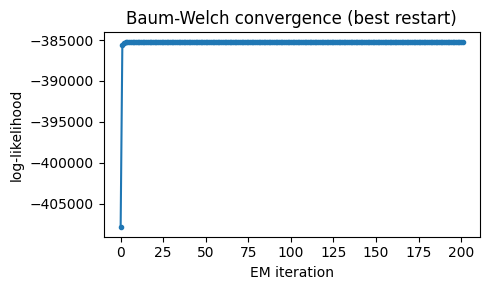

In [3]:
hmm = H.fit_hmm_g3_sym(seqs, n_restarts=3, max_iter=300, tol=1e-6, seed=0)
print("\nbest model:")
print(f"  loglik      : {hmm['loglik']:.1f}  ({hmm['n_iter']} iters)")
print(f"  sigma (fwd) : {hmm['sigma']:.2f} deg")
print(f"  turn Gamma  : alpha={hmm['alpha']:.2f}  theta={hmm['theta']:.2f} deg  "
      f"(mean turn = {hmm['alpha']*hmm['theta']:.1f} deg)")
print(f"  pi (F,L,R)  : {np.round(hmm['pi'],3)}")
print(f"  steady state: {np.round(H.steady_state(hmm['T']),3)}")
print("  T (from F,L,R):\n", np.round(hmm["T"], 3))

plt.figure(figsize=(5, 3))
plt.plot(hmm["history"], marker="."); plt.xlabel("EM iteration"); plt.ylabel("log-likelihood")
plt.title("Baum-Welch convergence (best restart)"); plt.tight_layout(); plt.show()

H.save_hmm(ROOT / "data" / "hmm_GsizeMotionSingle.npz", hmm)

## 4. Emission distributions vs data

Overlay the fitted emissions — forward `Normal(0, sigma)` and the two sign-flipped turn `Gamma(alpha, theta)` — weighted by the HMM steady-state occupancy, on the empirical `dtheta` histogram (paper Fig 2a / S2c). A good fit tracks the central peak and the turn shoulders.

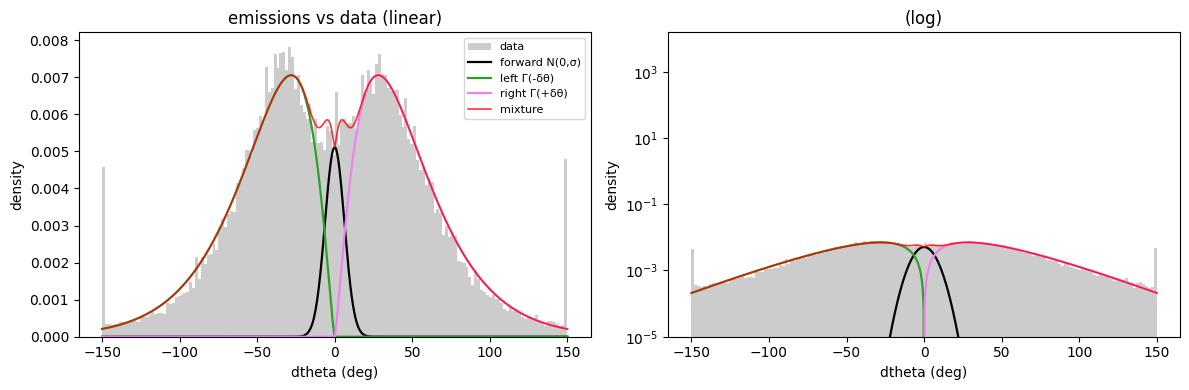

In [4]:
w = H.steady_state(hmm["T"])            # F, L, R occupancy = mixture weights
xg = np.linspace(-150, 150, 1001)
pdf_f = w[0] * norm.pdf(xg, 0, hmm["sigma"])
pdf_l = np.where(xg < 0, w[1] * gamma_dist.pdf(-xg, hmm["alpha"], scale=hmm["theta"]), 0)
pdf_r = np.where(xg > 0, w[2] * gamma_dist.pdf(xg, hmm["alpha"], scale=hmm["theta"]), 0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, logy in zip(ax, [False, True]):
    a.hist(np.clip(alld, -150, 150), bins=160, density=True, color="0.8", label="data")
    a.plot(xg, pdf_f, "k", lw=1.6, label="forward N(0,σ)")
    a.plot(xg, pdf_l, color="tab:green", lw=1.6, label="left Γ(-δθ)")
    a.plot(xg, pdf_r, color="violet", lw=1.6, label="right Γ(+δθ)")
    a.plot(xg, pdf_f + pdf_l + pdf_r, "r", lw=1.2, alpha=0.8, label="mixture")
    a.set_xlabel("dtheta (deg)"); a.set_ylabel("density")
    if logy:
        a.set_yscale("log"); a.set_ylim(1e-5, None)
ax[0].legend(fontsize=8); ax[0].set_title("emissions vs data (linear)"); ax[1].set_title("(log)")
plt.tight_layout(); plt.show()

## 5. Viterbi labeling of a real trajectory (MC vs HMM)

Like paper Fig 2b: take one real trajectory, label its bouts with the HMM (Viterbi) and with the MC threshold, and colour the 2-D path (using the stored onset positions `x_mm, y_mm`). The HMM uses context, so it can label small-angle bouts differently from the hard threshold.

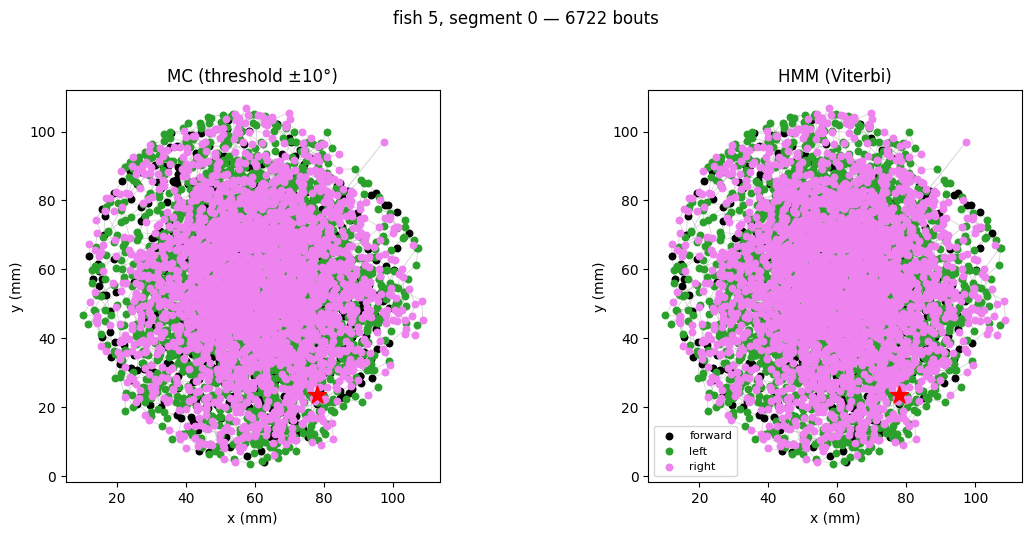

HMM relabels 5% of this trajectory's bouts vs the threshold


In [5]:
# pick a reasonably long trajectory
g = (df.sort_values(["fish_id", "segment_id", "bout_index"])
       .groupby(["fish_id", "segment_id"]))
key = max(g.groups, key=lambda k: len(g.get_group(k)))
traj = g.get_group(key)
dth = traj["dtheta_deg"].to_numpy(float)
xm, ym = traj["x_px"].to_numpy(float), traj["y_px"].to_numpy(float)

states_hmm = H.viterbi(dth, hmm)
states_mc = H.threshold_classifier([dth], dtheta0=H.DTHETA0_DEG)[0]
colors = {0: "k", 1: "tab:green", 2: "violet"}

fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
for a, st, title in [(ax[0], states_mc, "MC (threshold ±10°)"),
                     (ax[1], states_hmm, "HMM (Viterbi)")]:
    a.plot(xm, ym, lw=0.6, color="lightgray", zorder=1)
    for s in range(3):
        m = st == s
        a.scatter(xm[m], ym[m], s=22, color=colors[s], label=H.STATE_NAMES[s], zorder=2)
    a.scatter([xm[0]], [ym[0]], marker="*", s=180, color="red", zorder=3)
    a.set_aspect("equal"); a.set_xlabel("x (mm)"); a.set_ylabel("y (mm)"); a.set_title(title)
ax[1].legend(fontsize=8)
plt.suptitle(f"fish {key[0]}, segment {key[1]} — {len(dth)} bouts", y=1.02)
plt.tight_layout(); plt.show()

reclass = (states_hmm != states_mc).mean()
print(f"HMM relabels {reclass:.0%} of this trajectory's bouts vs the threshold")

## 6. Generate synthetic trajectories from the HMM

Sample a state sequence from the HMM, an angle from each emission, and resample `dt`/`dist` from the empirical pools; reconstruct the 2-D path (paper Fig 6e).

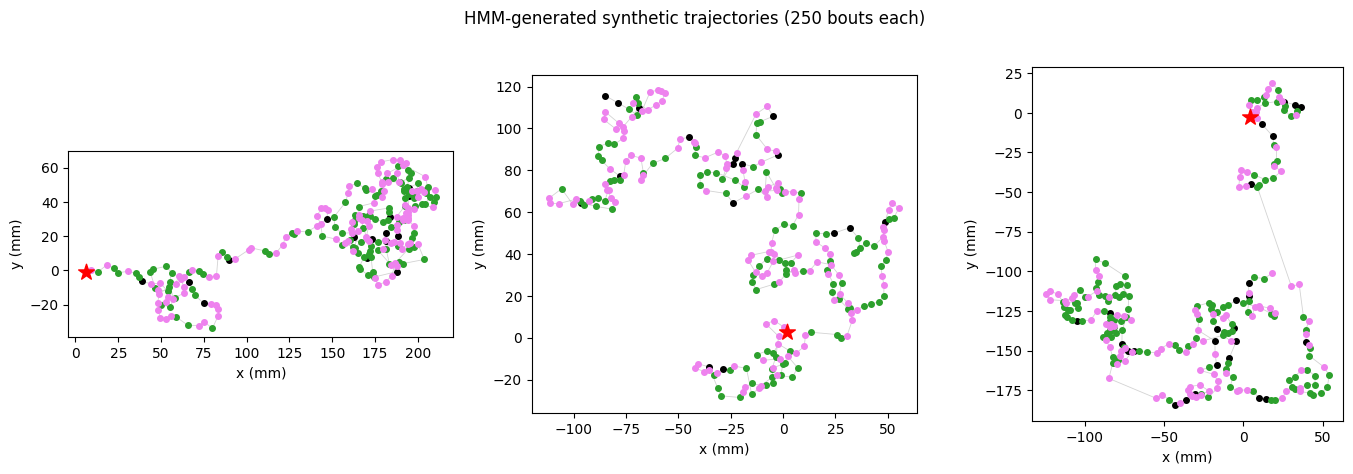

In [6]:
rng = np.random.default_rng(1)
dt_pool = df["dt_s"].dropna().to_numpy()
dist_pool = df["distance_px"].dropna().to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for a in axes:
    gen = H.generate_bouts(hmm, 250, dt_pool, dist_pool, rng)
    x, y, _ = H.reconstruct_xy(gen["angle_deg"], gen["dist_px"])
    a.plot(x, y, lw=0.6, color="lightgray", zorder=1)
    for s in range(3):
        m = gen["state"] == s
        a.scatter(x[m], y[m], s=16, color={0:"k",1:"tab:green",2:"violet"}[s], zorder=2)
    a.scatter([x[0]], [y[0]], marker="*", s=140, color="red", zorder=3)
    a.set_aspect("equal"); a.set_xlabel("x (mm)"); a.set_ylabel("y (mm)")
plt.suptitle("HMM-generated synthetic trajectories (250 bouts each)", y=1.02)
plt.tight_layout(); plt.show()

## 7. Distributions: real vs generated

Do the generated bout statistics match the data? Compare the reorientation angle, inter-bout interval and distance (paper Fig 6f). `dt`/`dist` match by construction (resampled from the data); `dtheta` tests whether the HMM emissions + transitions reproduce the angular statistics.

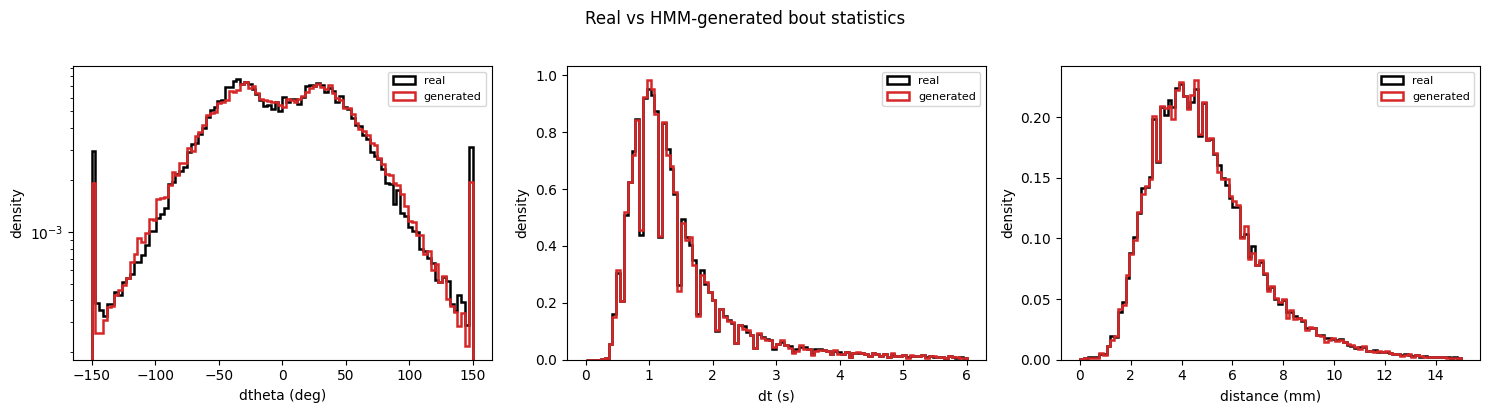

state fractions  real (MC-thresh): [0.111 0.448 0.44 ]  | HMM steady: [0.08 0.46 0.46]  | generated: [0.08 0.46 0.46]


: 

In [ ]:
big = H.generate_bouts(hmm, n_bouts, dt_pool, dist_pool, rng)
specs = [("dtheta (deg)", np.clip(alld, -150, 150), np.clip(big["angle_deg"], -150, 150), (-150, 150), True),
         ("dt (s)", df["dt_s"].dropna(), big["dt_s"], (0, 6), False),
         ("distance (mm)", df["distance_px"].dropna(), big["dist_px"], (0, 15), False)]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (xl, real, geni, rng_, logy) in zip(ax, specs):
    a.hist(real, bins=100, range=rng_, density=True, histtype="step", lw=1.8, color="k", label="real")
    a.hist(geni, bins=100, range=rng_, density=True, histtype="step", lw=1.8, color="tab:red", label="generated")
    a.set_xlabel(xl); a.set_ylabel("density")
    if logy:
        a.set_yscale("log")
    a.legend(fontsize=8)
plt.suptitle("Real vs HMM-generated bout statistics", y=1.02)
plt.tight_layout(); plt.show()

print("state fractions  real (MC-thresh):", np.round(pi_mc, 3),
      " | HMM steady:", np.round(H.steady_state(hmm["T"]), 3),
      " | generated:", np.round(np.bincount(big["state"], minlength=3) / n_bouts, 3))

## Notes & next steps

- **Optimiser**: Baum-Welch (EM), reproduced in `scripts/fit_hmm.py` (`fit_hmm_g3_sym`). This matches the paper's `ZebrafishHMM_G3_Sym` type (`HiddenMarkovModels.jl` Baum-Welch); the fitted models in the paper repo store exactly `sforw` + `turn=[alpha, theta]` + a symmetric transition matrix.
- **Batch/CLI**: `uv run scripts/fit_hmm.py` runs the same MC + HMM fit + generation headless and saves the model (`.npz`) and generated bouts (`.csv`).
- **Caveats for our data**: the broad `dtheta` (median |δθ| ≈ 39°) means a large forward `sigma` and overlapping states — the HMM still separates F/L/R but the emissions are far less crisp than the paper's. Options to explore: fit **per fish** (like the paper's single-fish HMMs), fit only the spontaneous `inter_stim_pause` bouts, relax left–right symmetry (our assay is laterally driven by the stimulus), or feed the sequences to the paper's Julia package for a cross-check.
- **Generation** currently resamples `dt`/`dist` globally (paper convention). To make trajectories condition-specific you could resample these per stimulus block.